In [1]:
import os
import pickle
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50, DenseNet121
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_curve, auc
)
from sklearn.preprocessing import label_binarize
import seaborn as sns
import matplotlib.pyplot as plt

# === Settings ===
train_dir = 'plntdata/Final_DataSet/train'
val_dir = 'plntdata/Final_DataSet/valid'
IMG_SIZE = (224, 224)
BATCH_SIZE = 96
EPOCHS = 26

# === Early stopping ===
early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)

# === Preprocessing functions for models ===
preprocess_map = {
    "ResNet50": resnet_preprocess,
    "DenseNet121": densenet_preprocess
}

# === Plot training curves ===
def plot_accuracy_loss(history, model_name):
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history['accuracy'], label='Train Accuracy')
    plt.plot(history['val_accuracy'], label='Val Accuracy')
    plt.title(f"{model_name} Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history['loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Val Loss')
    plt.title(f"{model_name} Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.savefig(f"{model_name}_accuracy_loss.png")
    plt.show()

# === Plot multi-class ROC curve ===
def plot_multiclass_roc(y_true, y_probs, class_names, model_name):
    y_true_bin = label_binarize(y_true, classes=range(len(class_names)))
    fpr, tpr, roc_auc = {}, {}, {}

    for i in range(len(class_names)):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_probs[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    plt.figure(figsize=(10, 8))
    for i in range(len(class_names)):
        plt.plot(fpr[i], tpr[i], label=f'{class_names[i]} (AUC = {roc_auc[i]:.2f})')

    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'{model_name} - ROC Curve')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.savefig(f"{model_name}_roc_curve.png")
    plt.show()

# === Train & Evaluate Model ===
def train_model(model_fn, model_name):
    print(f"\n=== Training: {model_name} ===")

    preprocess_func = preprocess_map[model_name]

    # === Data generators ===
    train_gen = ImageDataGenerator(preprocessing_function=preprocess_func).flow_from_directory(
        train_dir, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', shuffle=True
    )
    val_gen = ImageDataGenerator(preprocessing_function=preprocess_func).flow_from_directory(
        val_dir, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False
    )

    # === Base model ===
    base_model = model_fn(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False

    # === Full model ===
    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(train_gen.num_classes, activation='softmax')
    ])

    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

    # === Train ===
    history = model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=EPOCHS,
        callbacks=[early_stop],
        verbose=2
    )

    # === Save history ===
    with open(f"{model_name}_history.pkl", "wb") as f:
        pickle.dump(history.history, f)
    print(f"✅ Training history saved as {model_name}_history.pkl")

    # === Save model ===
    model.save(f"{model_name}_full_model.h5")
    print(f"✅ Full model saved as {model_name}_full_model.h5")

    # === Evaluate ===
    val_gen.reset()
    preds = model.predict(val_gen)
    y_pred = np.argmax(preds, axis=1)
    y_true = val_gen.classes
    labels = list(val_gen.class_indices.keys())

    # === Classification report ===
    print("\n📊 Classification Report:")
    print(classification_report(y_true, y_pred, target_names=labels))

    # === Metrics ===
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

    print(f"\n✅ Accuracy : {acc:.4f}")
    print(f"✅ Precision: {prec:.4f}")
    print(f"✅ Recall   : {rec:.4f}")
    print(f"✅ F1 Score : {f1:.4f}")

    # === Confusion matrix ===
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt="d", xticklabels=labels, yticklabels=labels, cmap="Blues")
    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.savefig(f"{model_name}_confusion_matrix.png")
    plt.show()

    # === Plots ===
    plot_accuracy_loss(history.history, model_name)
    plot_multiclass_roc(y_true, preds, labels, model_name)

    # === Clean up ===
    tf.keras.backend.clear_session()



=== Training: ResNet50 ===
Found 70295 images belonging to 38 classes.
Found 17572 images belonging to 38 classes.
Epoch 1/26
733/733 - 196s - loss: 0.7245 - accuracy: 0.7923 - val_loss: 0.1364 - val_accuracy: 0.9598 - 196s/epoch - 267ms/step
Epoch 2/26
733/733 - 193s - loss: 0.2611 - accuracy: 0.9177 - val_loss: 0.0894 - val_accuracy: 0.9722 - 193s/epoch - 263ms/step
Epoch 3/26
733/733 - 195s - loss: 0.2036 - accuracy: 0.9350 - val_loss: 0.0743 - val_accuracy: 0.9746 - 195s/epoch - 267ms/step
Epoch 4/26
733/733 - 203s - loss: 0.1739 - accuracy: 0.9429 - val_loss: 0.0669 - val_accuracy: 0.9790 - 203s/epoch - 277ms/step
Epoch 5/26
733/733 - 202s - loss: 0.1480 - accuracy: 0.9502 - val_loss: 0.0664 - val_accuracy: 0.9770 - 202s/epoch - 276ms/step
Epoch 6/26
733/733 - 199s - loss: 0.1383 - accuracy: 0.9539 - val_loss: 0.0510 - val_accuracy: 0.9812 - 199s/epoch - 271ms/step
Epoch 7/26
733/733 - 200s - loss: 0.1286 - accuracy: 0.9558 - val_loss: 0.0492 - val_accuracy: 0.9833 - 200s/epoch -

C:\ProgramData\anaconda3\envs\tf_cuda_env\lib\site-packages\keras\engine\functional.py:1410: CustomMaskWarning: Custom mask layers require a config and must override get_config. When loading, the custom mask layer must be passed to the custom_objects argument.
  layer_config = serialize_layer_fn(layer)


✅ Full model saved as ResNet50_full_model.h5

📊 Classification Report:
                                            precision    recall  f1-score   support

                          Apple_BlackRot_0       1.00      1.00      1.00       497
                         Apple_CedarRust_1       1.00      1.00      1.00       440
                           Apple_Healthy_2       0.99      1.00      1.00       502
                              Apple_Scab_3       1.00      0.99      1.00       504
                       Blueberry_Healthy_4       1.00      1.00      1.00       454
                          Cherry_Healthy_5       0.99      1.00      1.00       456
                    Cherry_PowderyMildew_6       1.00      1.00      1.00       421
     Corn_Maize_Cercospora_Grey_LeafSpot_7       0.96      0.93      0.95       410
                   Corn_Maize_CommonRust_8       1.00      1.00      1.00       477
                      Corn_Maize_Healthy_9       1.00      1.00      1.00       465
    

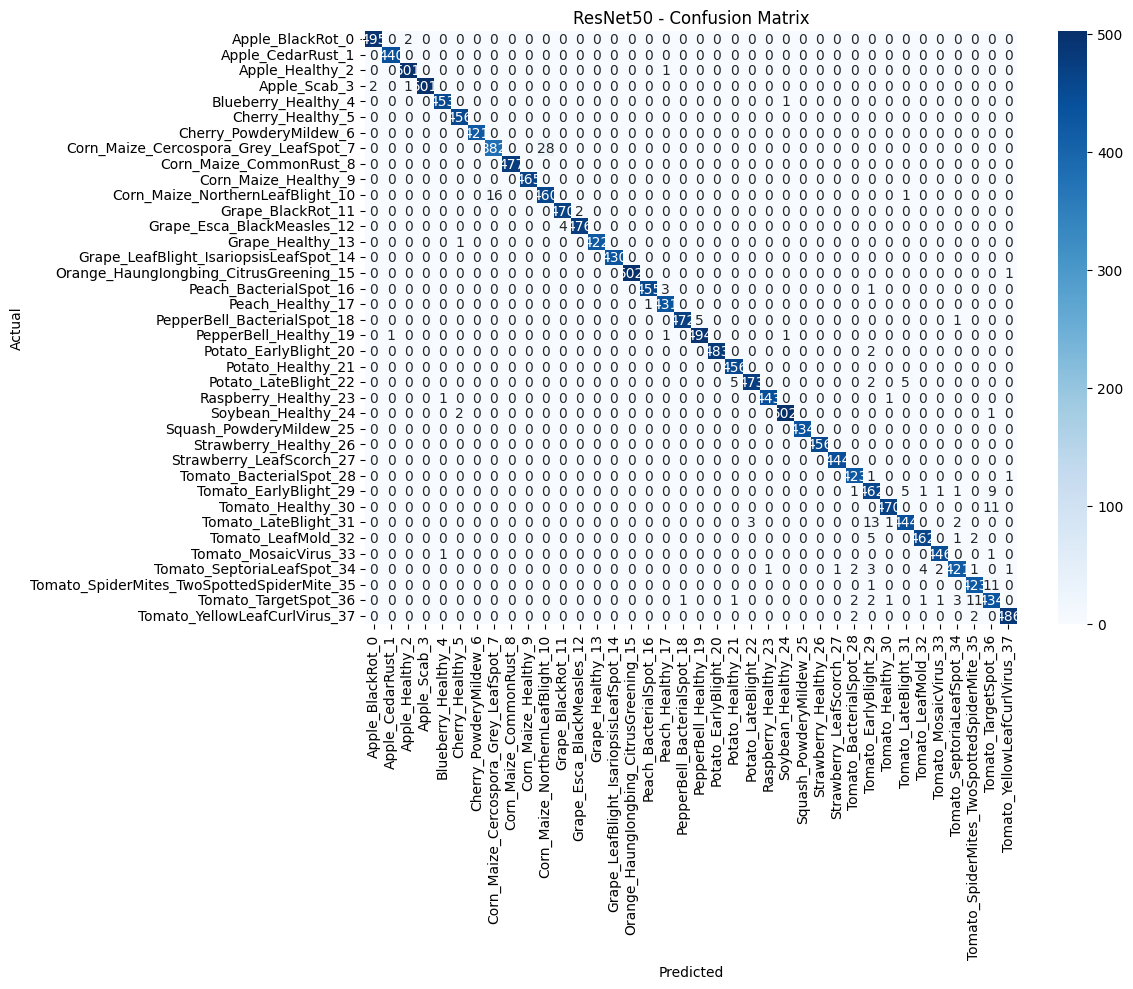

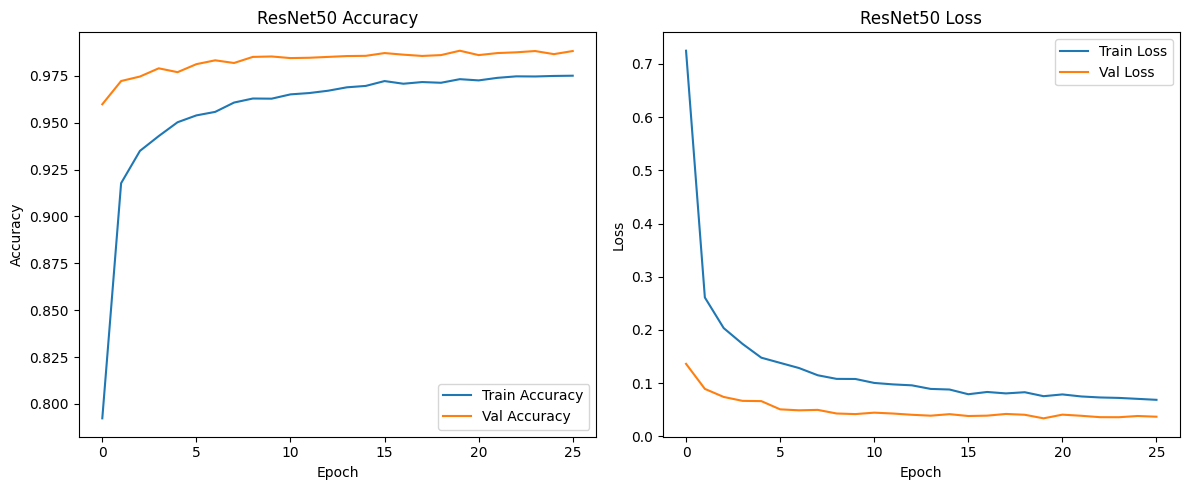

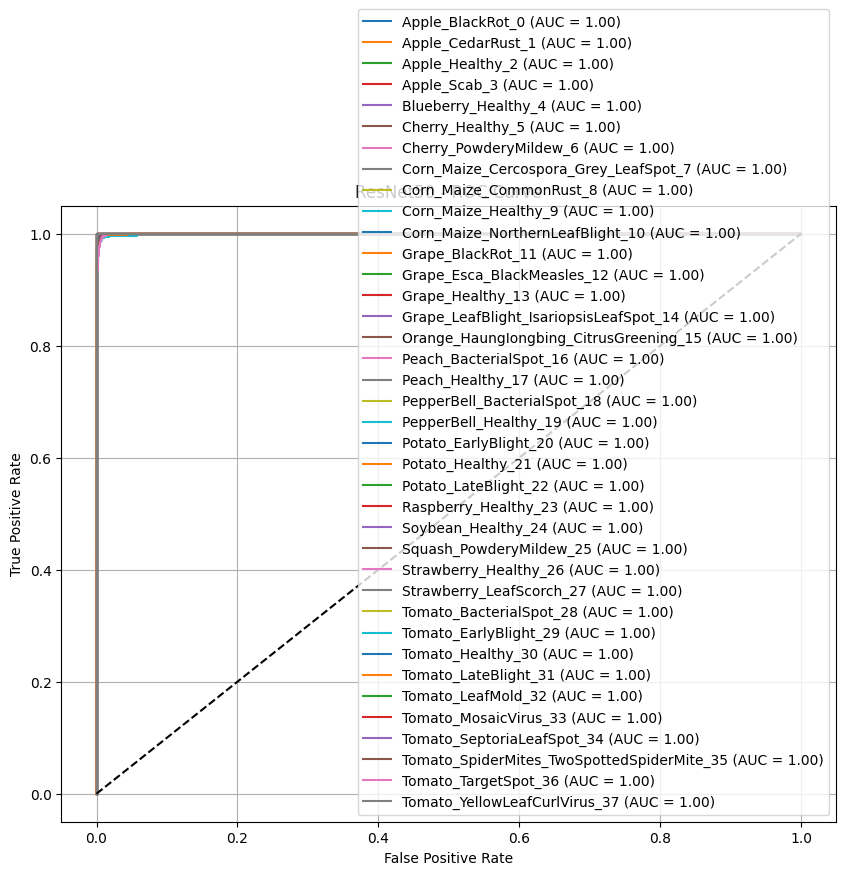

In [2]:
train_model(ResNet50, "ResNet50")


=== Training: DenseNet121 ===
Found 70295 images belonging to 38 classes.
Found 17572 images belonging to 38 classes.
Epoch 1/26
733/733 - 223s - loss: 1.0620 - accuracy: 0.6953 - val_loss: 0.2532 - val_accuracy: 0.9350 - 223s/epoch - 304ms/step
Epoch 2/26
733/733 - 213s - loss: 0.4189 - accuracy: 0.8696 - val_loss: 0.1707 - val_accuracy: 0.9502 - 213s/epoch - 291ms/step
Epoch 3/26
733/733 - 212s - loss: 0.3204 - accuracy: 0.8970 - val_loss: 0.1282 - val_accuracy: 0.9624 - 212s/epoch - 289ms/step
Epoch 4/26
733/733 - 212s - loss: 0.2753 - accuracy: 0.9096 - val_loss: 0.1119 - val_accuracy: 0.9645 - 212s/epoch - 290ms/step
Epoch 5/26
733/733 - 209s - loss: 0.2452 - accuracy: 0.9199 - val_loss: 0.1030 - val_accuracy: 0.9657 - 209s/epoch - 285ms/step
Epoch 6/26
733/733 - 208s - loss: 0.2307 - accuracy: 0.9236 - val_loss: 0.0999 - val_accuracy: 0.9680 - 208s/epoch - 284ms/step
Epoch 7/26
733/733 - 216s - loss: 0.2144 - accuracy: 0.9286 - val_loss: 0.0914 - val_accuracy: 0.9701 - 216s/epoc

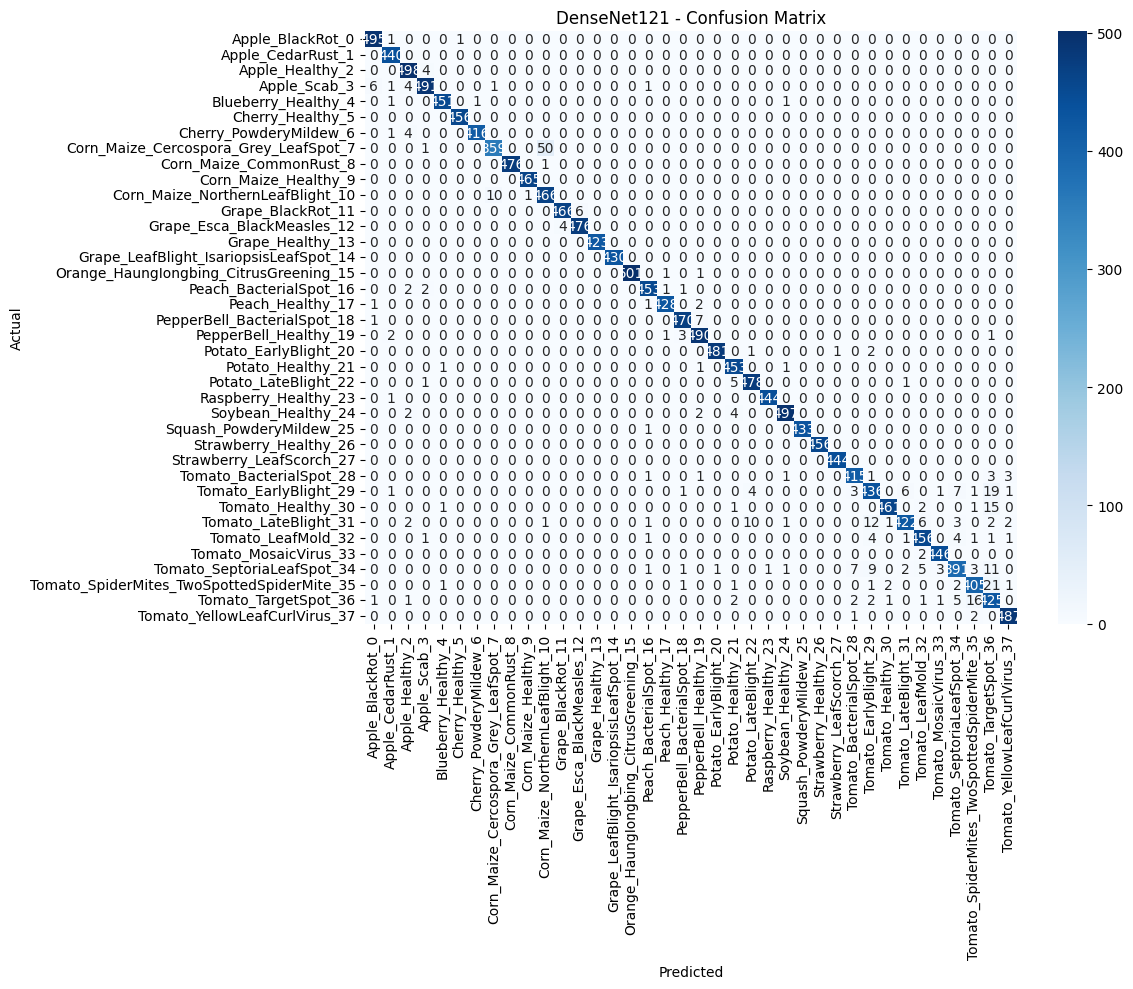

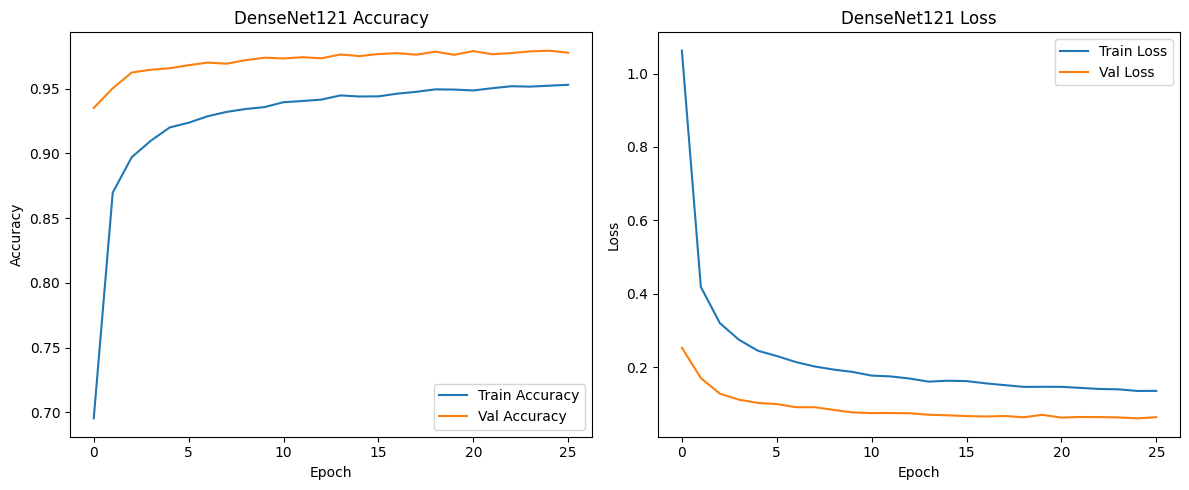

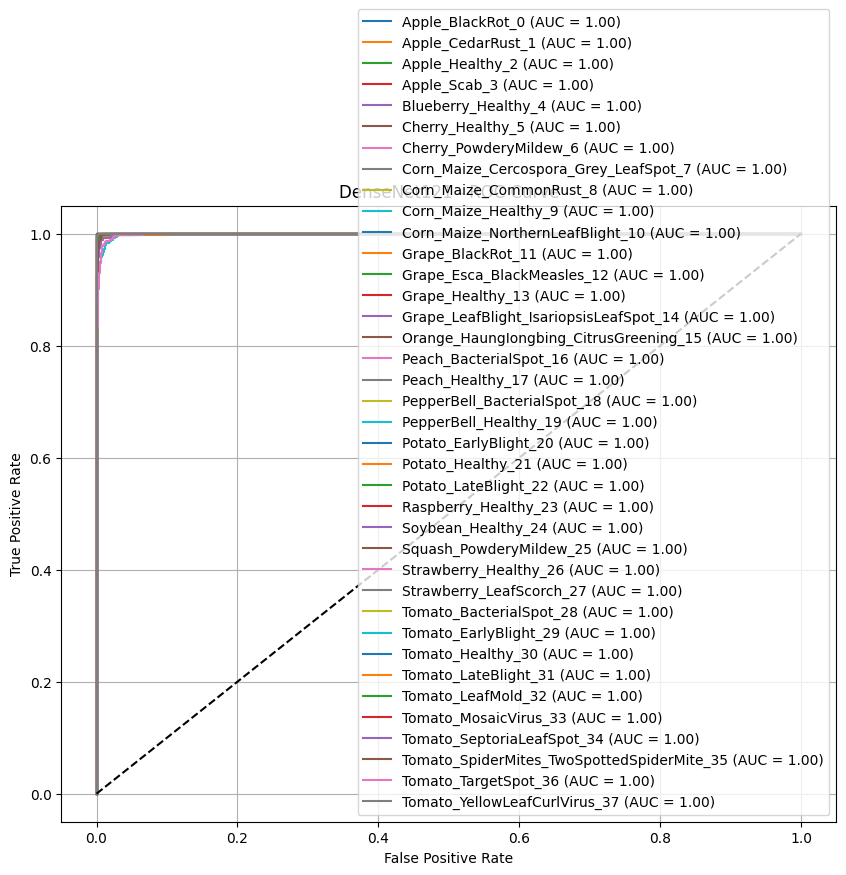

In [3]:
train_model(DenseNet121, "DenseNet121")